In [1]:
import numpy as np
import os

A = np.load("/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/cell_oracle_run/cell_oracle_global_A/A_celloracle.npy")
A_genes = np.load("/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/cell_oracle_run/cell_oracle_global_A/A_genes.npy", allow_pickle=True)
A_tfs   = np.load("/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/cell_oracle_run/cell_oracle_global_A/A_tfs.npy", allow_pickle=True)

print(A.shape)

(277, 2995)


In [2]:
import anndata as ad

adata = ad.read_h5ad("/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/velten_rna.h5ad")
X_full = adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X
gene_names = list(adata.var_names)

In [3]:
gene_to_idx = {g: i for i, g in enumerate(gene_names)}

# align TFs
tf_mask = np.array([tf in gene_to_idx for tf in A_tfs])

A = A[tf_mask, :]
A_tfs = A_tfs[tf_mask]

tf_idx = np.array([gene_to_idx[tf] for tf in A_tfs])

# align genes
gene_mask = np.array([g in gene_to_idx for g in A_genes])

A = A[:, gene_mask]
A_genes = A_genes[gene_mask]

gene_idx = np.array([gene_to_idx[g] for g in A_genes])

# align X to same gene space as A
X = X_full[:, gene_idx]

subset_gene_names = np.array(A_genes)  # THIS is the column order of X
subset_gene_to_idx = {g: i for i, g in enumerate(subset_gene_names)}

tf_idx = np.array([
    subset_gene_to_idx[tf]
    for tf in A_tfs
    if tf in subset_gene_to_idx
])

tf_mask = np.array([tf in subset_gene_to_idx for tf in A_tfs])

A = A[tf_mask, :]
A_tfs = A_tfs[tf_mask]

tf_idx = np.array([subset_gene_to_idx[tf] for tf in A_tfs])

# build x_TF
X_TF = X[:, tf_idx]

V_pred = X_TF @ A
np.save("V_pred.npy", V_pred)
np.save("gene_idx.npy", gene_idx)

/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


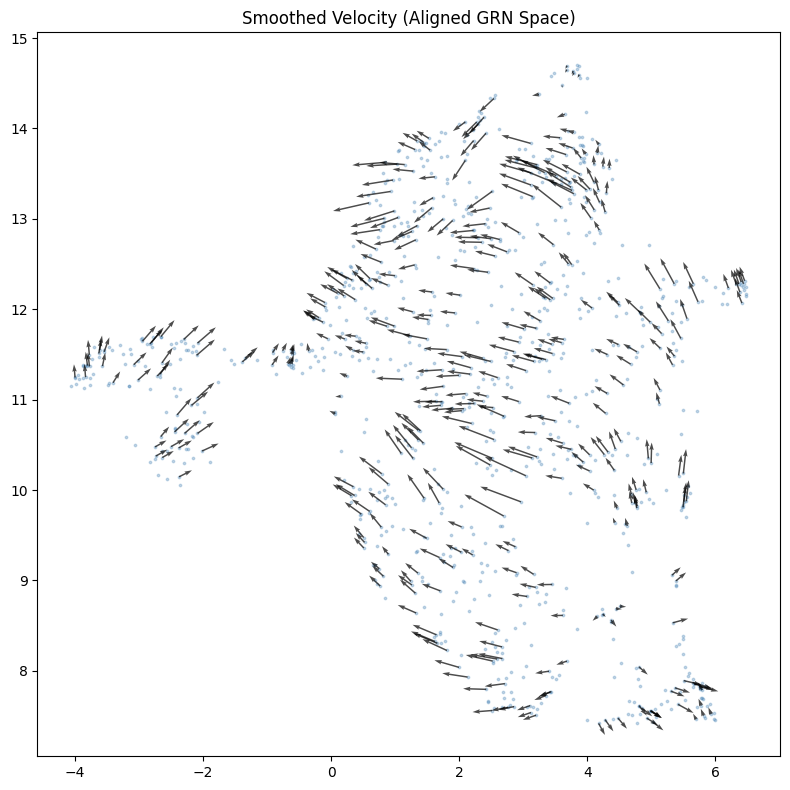

In [4]:
# visualize_velocity.py
import numpy as np
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from umap import UMAP

# =========================
# 1. Load data (ONLY ONCE)
# =========================
adata = ad.read_h5ad("/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/velten_rna.h5ad")

V_pred = np.load("V_pred.npy")          # (cells × genes_used_in_model)
gene_idx = np.load("gene_idx.npy")      # alignment used during training

X_full = adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X

# =========================
# 2. Reconstruct aligned X
# =========================
X = X_full[:, gene_idx]

# sanity check (IMPORTANT)
assert X.shape[0] == V_pred.shape[0], "Cell mismatch between X and V_pred"
assert X.shape[1] == V_pred.shape[1], "Gene mismatch between X and V_pred"

# =========================
# 3. UMAP on aligned space
# =========================
reducer = UMAP(n_neighbors=15, random_state=42)
X_umap = reducer.fit_transform(X)

# =========================
# 4. Velocity projection
# =========================
eps = 0.5

X_perturbed = X + eps * V_pred
X_pert_umap = reducer.transform(X_perturbed)

V_umap_raw = (X_pert_umap - X_umap) / eps

# =========================
# 5. Smooth velocity (UMAP neighborhood averaging)
# =========================
nn = NearestNeighbors(n_neighbors=30).fit(X_umap)
_, idx = nn.kneighbors(X_umap)

V_umap_smooth = np.array([
    V_umap_raw[idx[i]].mean(axis=0)
    for i in range(len(X_umap))
])

# =========================
# 6. Plot
# =========================
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    X_umap[:, 0], X_umap[:, 1],
    s=3, alpha=0.3, c="steelblue"
)

sample = np.random.choice(len(X_umap), 400, replace=False)

ax.quiver(
    X_umap[sample, 0], X_umap[sample, 1],
    V_umap_smooth[sample, 0], V_umap_smooth[sample, 1],
    alpha=0.7, scale=10, width=0.002, color="black"
)

ax.set_title("Smoothed Velocity (Aligned GRN Space)")
plt.tight_layout()
plt.savefig("velocity_final.png", dpi=150)
plt.show()

In [5]:
adata

AnnData object with n_obs × n_vars = 1035 × 12553
    obs: 'plate', 'well', 'facs_fsc.area', 'facs_fsc_height', 'facs_ssc.area', 'facs_ssc_height', 'facs_cd45ra', 'facs_cd135', 'facs_cd90', 'facs_cd49f', 'facs_lin', 'facs_cd34', 'facs_cd38', 'facs_cd10', 'culture_key', 'culture_cells_in_colony', 'culture_mk_cd41+', 'culture_ery_cd235+', 'culture_total_number_of_my_cd33+', 'facs_pseudotime', 'fate_stemness', 'n_genes', 'dpt_pseudotime'
    var: 'n_cells'
    obsm: 'X_diffmap', 'X_pca', 'X_umap'
    layers: 'counts'

In [9]:
from scipy.stats import spearmanr

score = spearmanr(
    adata.obs["facs_pseudotime"][:-1],
    np.sum(V_pred[:-1] * (X[1:] - X[:-1]), axis=1)
)[0]

print(score)

-0.07848092977044865


In [4]:
import numpy as np
import os

A = np.load("/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/cell_oracle_run/cell_oracle_global_A/A_celloracle.npy")
A_genes = np.load("/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/cell_oracle_run/cell_oracle_global_A/A_genes.npy", allow_pickle=True)
A_tfs   = np.load("/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/cell_oracle_run/cell_oracle_global_A/A_tfs.npy", allow_pickle=True)

print(A.shape)

(277, 2995)


In [5]:
# find shared genes
gene_idx = []
valid_genes = []

for j, g in enumerate(A_genes):
    if g in gene_names:
        gene_idx.append(j)
        valid_genes.append(gene_names.index(g))

# subset A (columns)
A = A[:, gene_idx]

# subset RNA (columns)
X_full = X_full[:, valid_genes]

print("Aligned shapes:")
print("X_full:", X_full.shape)
print("A:", A.shape)

Aligned shapes:
X_full: (1035, 2995)
A: (277, 2995)


In [91]:
import numpy as np
from sklearn.decomposition import NMF
from sklearn.metrics.pairwise import cosine_similarity
from scipy.optimize import linear_sum_assignment

# Use the raw A (not thresholded to positive only)
# Split into pos/neg and stack — standard trick for signed matrices with NMF
A_pos = np.maximum(A, 0)   # shape G x T
A_neg = np.maximum(-A, 0)
A_nn = np.vstack([A_pos, A_neg])  # (2*G) x T — now non-negative

A2 = np.log1p(np.maximum(A, 0))
A2[A2 < 0.05] = 0

K = 7  # start smaller

Us = []
for seed in range(10):
    model = NMF(
        n_components=K,
        random_state=seed,
        max_iter=2000,
        init='random',      # much better init than random
    )
    U = model.fit_transform(A2)   # (2*G) x K
    # Normalize columns for comparison
    U_norm = U / (np.linalg.norm(U, axis=0, keepdims=True) + 1e-8)
    Us.append(U_norm)

# Compare with Hungarian matching (handles permutation)
sims = []
for i in range(1, 10):
    sim = cosine_similarity(Us[0].T, Us[i].T)  # K x K
    # Use Hungarian algorithm to find best permutation
    row_ind, col_ind = linear_sum_assignment(-sim)
    matched_sim = sim[row_ind, col_ind].mean()
    sims.append(matched_sim)

print(f"Mean matched cosine similarity: {np.mean(sims):.3f} ± {np.std(sims):.3f}")

Mean matched cosine similarity: 0.885 ± 0.082


In [92]:
gene_names = np.array(gene_names)
for k in range(K):
    top_genes = np.argsort(-U[:, k])[:30]
    print(k, gene_names[top_genes])


0 ['NDUFAF7' 'TFPI' 'PHTF2' 'ZNF207' 'KRIT1' 'JARID2' 'LAP3' 'GTF2IRD1'
 'ICA1' 'HEBP1' 'ITGA2B' 'CRY1' 'MAP4K3' 'TMEM159' 'SCYL3' 'HEATR5B'
 'FAM76A' 'RPAP3' 'LASP1' 'PAFAH1B1' 'CAMKK1' 'THSD7A' 'ARF5' 'LIG3'
 'ERCC1' 'XYLT2' 'CCDC109B' 'NUB1' 'SYN1' 'SLC25A39']
1 ['LASP1' 'CLK1' 'PTBP1' 'CDKL3' 'C1orf112' 'MTMR11' 'LUC7L' 'ELOVL5'
 'MBTD1' 'PROM1' 'FYN' 'ITGA2B' 'PPP5C' 'CRY1' 'ST3GAL1' 'ENSG00000005955'
 'ZNF207' 'CEP68' 'ACPP' 'VTA1' 'CALCOCO1' 'IFRD1' 'GTF2IRD1' 'FUCA2'
 'HEATR5B' 'STPG1' 'DHX33' 'NDUFAB1' 'PAFAH1B1' 'CFLAR']
2 ['ADAM22' 'HEATR5B' 'ST3GAL1' 'C19orf60' 'RPAP3' 'MPO' 'CYTH3' 'TMEM98'
 'SLC25A39' 'ELOVL5' 'XYLT2' 'CRAMP1' 'CLK1' 'C1orf112' 'EXTL3' 'ZNF263'
 'METTL13' 'MAP3K14' 'GGCT' 'TRAPPC6A' 'ICA1' 'CEP68' 'ACPP' 'TSPAN6'
 'CALCOCO1' 'LAP3' 'PPP5C' 'CFLAR' 'DNASE1L1' 'MAD1L1']
3 ['LYPLA2' 'RHBDF1' 'GDE1' 'TRAF3IP3' 'CLK1' 'PRSS21' 'HIVEP2' 'SLC30A9'
 'ENSG00000005189' 'SLC25A39' 'PAFAH1B1' 'CDKL3' 'CCDC124' 'STPG1' 'DDX11'
 'RANBP9' 'TTC22' 'SLC25A13' 'BTBD7' 'ZBT

In [93]:
import time
import gseapy as gp

for k in range(K):
    top_genes = list(gene_names[np.argsort(-U[:, k])[:100]])

    enr = gp.enrichr(
        gene_list=top_genes,
        gene_sets=['MSigDB_Hallmark_2020', 'Reactome_2022', 'KEGG_2021_Human'],
        outdir=None,
        cutoff=0.05
    )

    print(f"\n=== Component {k} ===")
    print(enr.results[['Term','Adjusted P-value','Overlap']].head(5))

    time.sleep(1.0)   # <-- prevents API disconnects



=== Component 0 ===
                              Term  Adjusted P-value Overlap
0                  G2-M Checkpoint          0.054843   5/200
1                  heme Metabolism          0.054843   5/200
2                       DNA Repair          0.075150   4/150
3  Reactive Oxygen Species Pathway          0.206177    2/49
4                   UV Response Dn          0.215576   3/144

=== Component 1 ===
               Term  Adjusted P-value Overlap
0   G2-M Checkpoint          0.198807   4/200
1        Complement          0.198807   4/200
2  mTORC1 Signaling          0.198807   4/200
3    UV Response Dn          0.246871   3/144
4        DNA Repair          0.246871   3/150

=== Component 2 ===
                              Term  Adjusted P-value Overlap
0                       Complement          0.204831   4/200
1                 mTORC1 Signaling          0.204831   4/200
2                       Glycolysis          0.204831   4/200
3  Reactive Oxygen Species Pathway          0.21242

In [94]:
print("shape:", A.shape)
print("density:", np.mean(A != 0))
print("min:", A.min(), "max:", A.max())

row_sums = np.sum(np.abs(A), axis=1)
col_sums = np.sum(np.abs(A), axis=0)

print("row sparsity:", np.percentile(row_sums, [0, 50, 99]))
print("col sparsity:", np.percentile(col_sums, [0, 50, 99]))

shape: (277, 2995)
density: 0.3264345509664121
min: -0.17322004 max: 0.45764726
row sparsity: [ 0.62647682  6.33868217 20.35299072]
col sparsity: [0.02512123 0.57767212 1.89078358]


In [14]:
print("Any zero columns:", np.any(np.linalg.norm(U, axis=0) == 0))


Any zero columns: True


In [95]:
import time
import gseapy as gp
import numpy as np
import pandas as pd

enrichment_results = {}   # <-- store everything here

for k in range(K):
    top_genes = list(gene_names[np.argsort(-U[:, k])[:100]])

    enr = gp.enrichr(
        gene_list=top_genes,
        gene_sets=['MSigDB_Hallmark_2020', 'Reactome_2022', 'KEGG_2021_Human'],
        outdir=None,
        cutoff=0.05
    )

    df = enr.results[['Term', 'Adjusted P-value', 'P-value', 'Overlap']].copy()

    enrichment_results[k] = df

    print(f"\n=== Component {k} ===")
    print(df.head(5))

    time.sleep(1.0)


=== Component 0 ===
                              Term  Adjusted P-value   P-value Overlap
0                  G2-M Checkpoint          0.054843  0.003324   5/200
1                  heme Metabolism          0.054843  0.003324   5/200
2                       DNA Repair          0.075150  0.006832   4/150
3  Reactive Oxygen Species Pathway          0.206177  0.024991    2/49
4                   UV Response Dn          0.215576  0.035633   3/144

=== Component 1 ===
               Term  Adjusted P-value   P-value Overlap
0   G2-M Checkpoint          0.198807  0.018073   4/200
1        Complement          0.198807  0.018073   4/200
2  mTORC1 Signaling          0.198807  0.018073   4/200
3    UV Response Dn          0.246871  0.035633   3/144
4        DNA Repair          0.246871  0.039464   3/150

=== Component 2 ===
                              Term  Adjusted P-value   P-value Overlap
0                       Complement          0.204831  0.018073   4/200
1                 mTORC1 Signalin

In [96]:
all_terms = sorted({
    term for df in enrichment_results.values() for term in df["Term"]
})

heatmap_mat = pd.DataFrame(
    0.0,
    index=range(K),
    columns=all_terms
)

for k, df in enrichment_results.items():
    for _, row in df.iterrows():
        term = row["Term"]
        p = row["P-value"]

        heatmap_mat.loc[k, term] = -np.log10(p + 1e-12)

In [97]:
top_terms = set()

for k, df in enrichment_results.items():
    top_terms.update(
        df.nsmallest(10, "P-value")["Term"]
    )

heatmap_mat_filtered = heatmap_mat[list(top_terms)]


/tmp/ipykernel_7152/1056530271.py:15: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


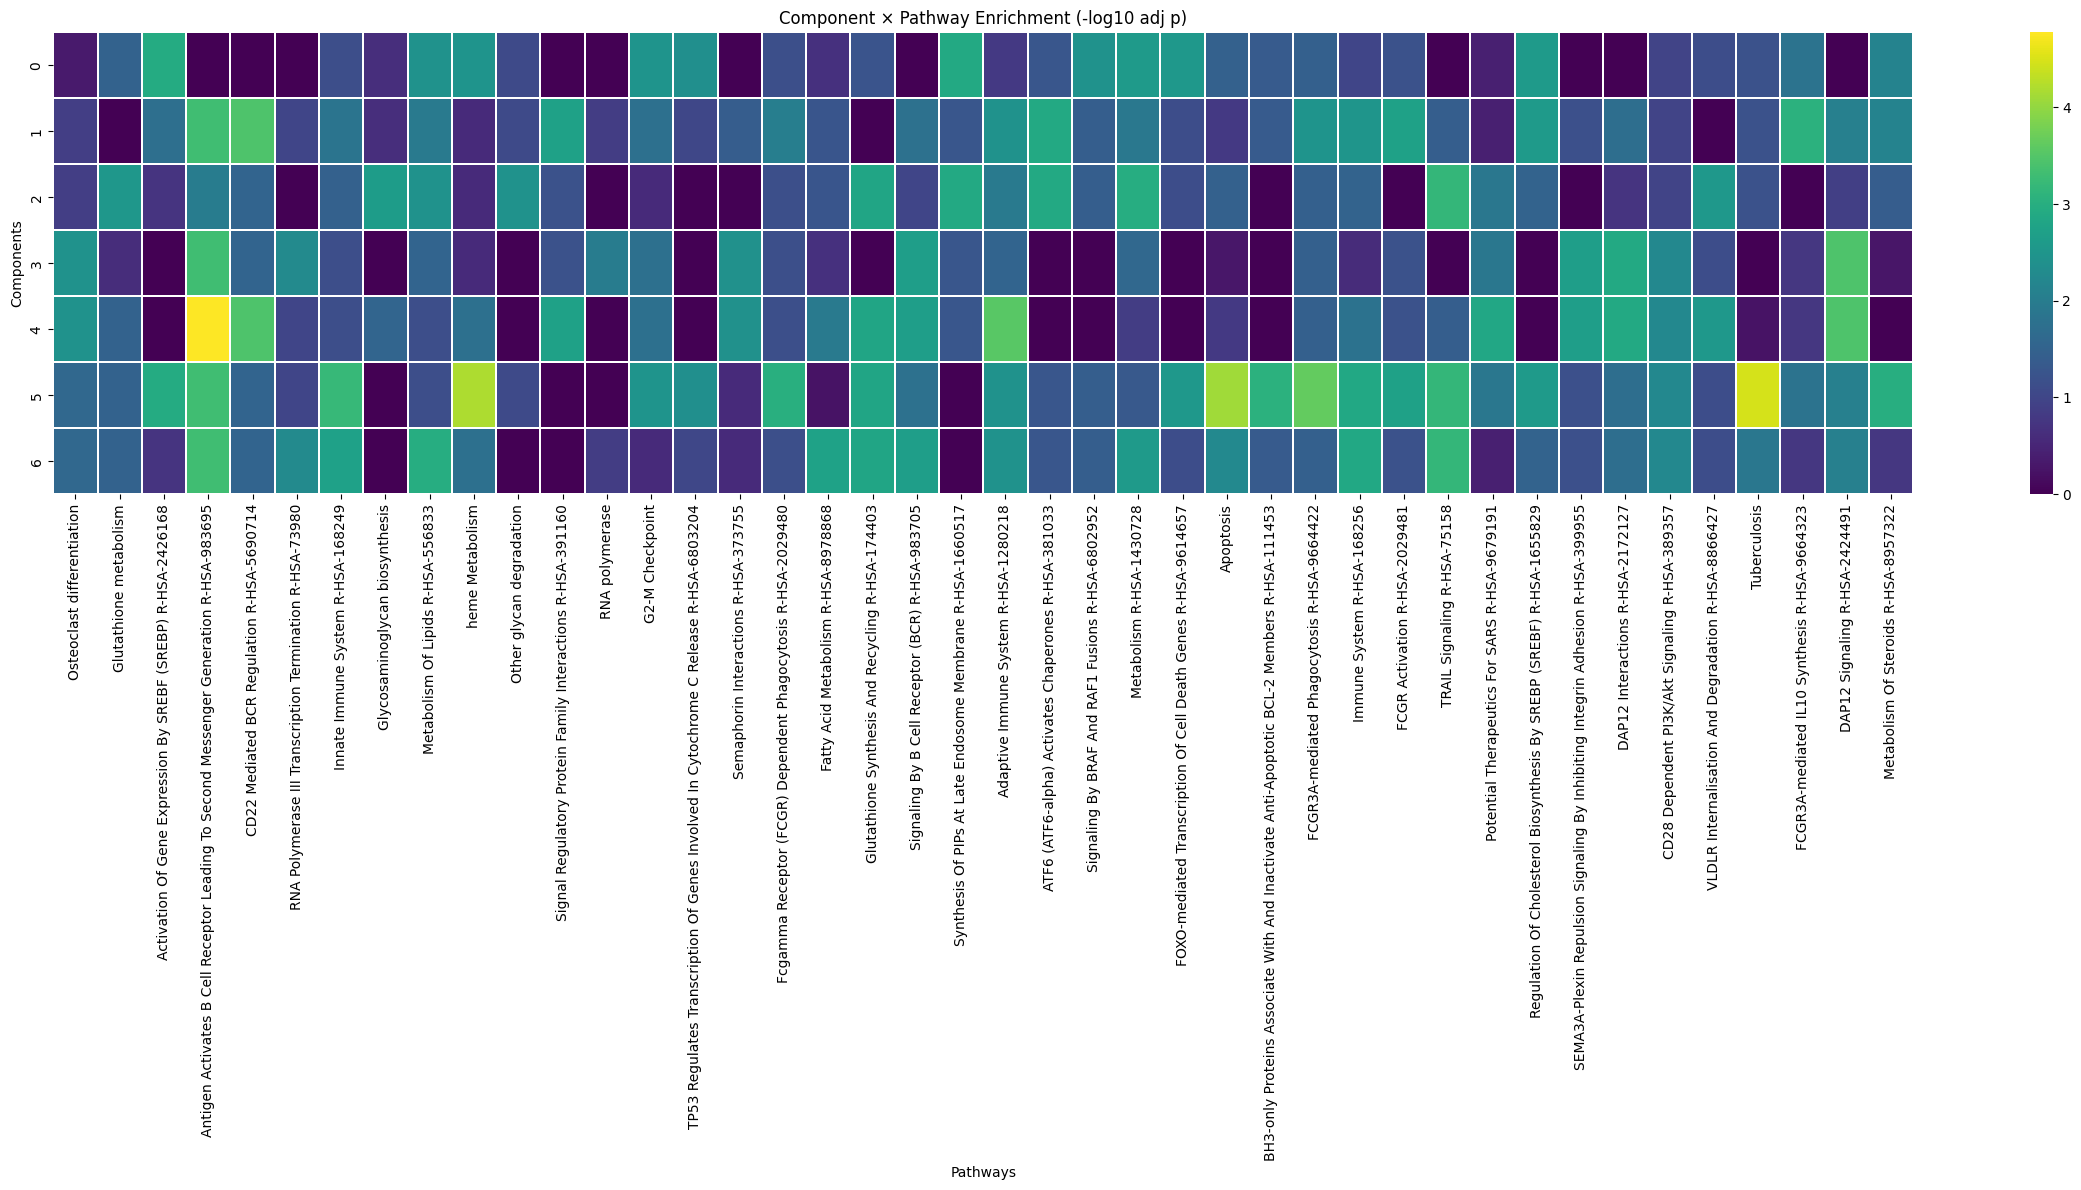

In [98]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(30, 6))

sns.heatmap(
    heatmap_mat_filtered,
    cmap="viridis",
    linewidths=0.2
)

plt.title("Component × Pathway Enrichment (-log10 adj p)")
plt.xlabel("Pathways")
plt.ylabel("Components")
plt.tight_layout()
plt.show()

In [69]:
import networkx as nx
G = nx.Graph()

for k, df in enrichment_results.items():
    comp_node = f"C{k}"
    G.add_node(comp_node, type="component")

    for _, row in df.iterrows():
        term = row["Term"]
        score = -np.log10(row["Adjusted P-value"] + 1e-12)

        G.add_node(term, type="pathway")

        G.add_edge(comp_node, term, weight=score)

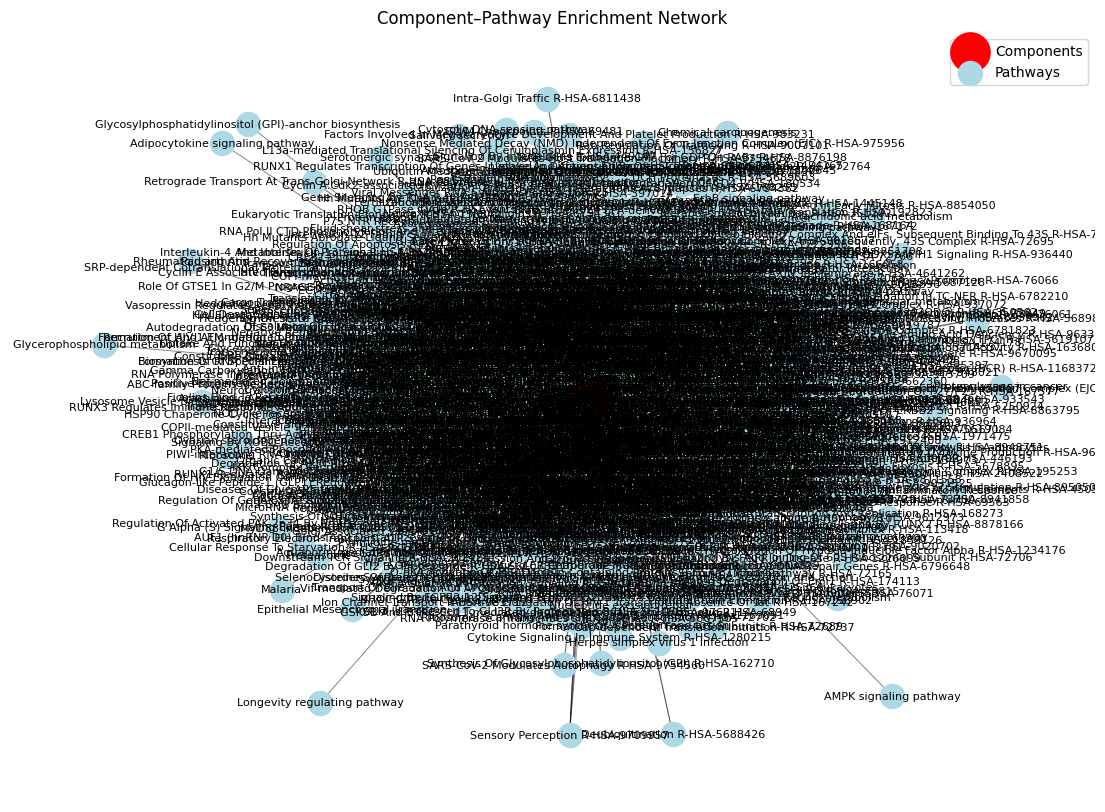

In [70]:
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(G, seed=0, k=0.8)

# separate node types
components = [n for n, d in G.nodes(data=True) if d["type"] == "component"]
pathways = [n for n, d in G.nodes(data=True) if d["type"] == "pathway"]

nx.draw_networkx_nodes(G, pos,
                       nodelist=components,
                       node_color="red",
                       node_size=800,
                       label="Components")

nx.draw_networkx_nodes(G, pos,
                       nodelist=pathways,
                       node_color="lightblue",
                       node_size=300,
                       label="Pathways")

# edges weighted
edges = G.edges(data=True)
weights = [d["weight"] for (_, _, d) in edges]

nx.draw_networkx_edges(
    G, pos,
    width=[0.5 + w for w in weights],
    alpha=0.5
)

nx.draw_networkx_labels(G, pos, font_size=8)

plt.title("Component–Pathway Enrichment Network")
plt.axis("off")
plt.legend()
plt.show()

# Other methods

In [55]:
import numpy as np
from sklearn.decomposition import NMF
from sklearn.metrics.pairwise import cosine_similarity
from scipy.optimize import linear_sum_assignment

A_pos = np.maximum(A, 0)

A_log = np.log1p(A_pos)
A_log = A_log 

K = 10
Ws = []

for seed in range(20):
    model = NMF(
        n_components=K,
        init="random",
        solver="mu",
        beta_loss="kullback-leibler",
        alpha_W=0.2,
        l1_ratio=0.9,
        max_iter=4000,
        random_state=seed
    )

    W = model.fit_transform(A_log)
    W = W / (np.linalg.norm(W, axis=0, keepdims=True) + 1e-8)
    Ws.append(W)

# stability
sims = []

for i in range(1, len(Ws)):
    sim = cosine_similarity(Ws[0].T, Ws[i].T)
    row_ind, col_ind = linear_sum_assignment(-sim)
    sims.append(sim[row_ind, col_ind].mean())

print(np.mean(sims), np.std(sims))

0.11051375 0.020904928


In [47]:
spca = SparsePCA(
    n_components=10,
    alpha=1.0,        # ↑ sparsity = ↑ modularity
    ridge_alpha=0.01,
    random_state=0,
    max_iter=2000
)

S = spca.fit_transform(A_stack)
W = spca.components_.T

In [45]:
sims = []

for i in range(1, len(Ws)):
    sim = cosine_similarity(Ws[0].T, Ws[i].T)

    row_ind, col_ind = linear_sum_assignment(-sim)
    sims.append(sim[row_ind, col_ind].mean())

print("ICA stability:", np.mean(sims), "±", np.std(sims))

ICA stability: 0.5184678 ± 0.18043603
